# Task 1

In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "data"

In [132]:
def read_data(path, columns, keep, chunksize=2_000_000):
    filtered_pieces = []
    for chunk in pd.read_csv(path, sep="|", usecols=columns, chunksize=chunksize):
        filtered = chunk[keep(chunk)]
        filtered = filtered.drop_duplicates()
        filtered_pieces.append(filtered)
    result = pd.concat(filtered_pieces, ignore_index=True)
    result = result.drop_duplicates()
    return result


In [133]:
patents = read_data(
    f"{DATA_PATH}/202608_EPO_IPC.txt",
    columns=["appln_id", "prio_year"],
    keep=lambda d: (d["prio_year"] >= 2000) & (d["prio_year"] <= 2019),
)

In [134]:
patents.head(5)

,appln_id,prio_year
0,8,2000
1,10,2000
2,11,2000
3,12,2000
4,13,2000


In [135]:
cpc = read_data(
    f"{DATA_PATH}/202608_CPC_Classes.txt",
    columns=["appln_id", "CPC_Class"],
    keep=lambda d: (
        d["CPC_Class"].str.startswith("Y02E", na=False)
        & d["appln_id"].isin(patents["appln_id"])
    ),
)

In [152]:
patents["green"] = patents["appln_id"].isin(cpc["appln_id"])


In [137]:
cpc.head(5)

,appln_id,CPC_Class
0,91,Y02E 30/00
1,91,Y02E 30/30
2,103,Y02E 20/16
3,146,Y02E 10/72
4,146,Y02E 10/76


In [138]:
applicants = read_data(
    f"{DATA_PATH}/202608_EPO_App_reg.txt",
    columns=["appln_id", "app_name", "ctry_code", "app_share"],
    keep=lambda d: d["appln_id"].isin(patents["appln_id"]),
)

In [139]:
applicants.head(5)

,appln_id,app_name,ctry_code,app_share
0,8,BABCOCK-HITACHI KABUSHIKI KAISHA,JP,1.0
1,10,Saltigo GmbH,DE,1.0
2,11,HONDA GIKEN KOGYO KABUSHIKI KAISHA,JP,1.0
3,12,Institut für Angewandte Chemie Berlin-Adlersho...,DE,1.0
4,13,NEC Electronics Corporation,JP,1.0


### check the data

In [140]:
print(f"The number of patent applications: {len(patents):,.0f}")
print(f"The number of green patent applications: {cpc['appln_id'].nunique():,.0f}")
print(f"The sum of all app_share is: {applicants['app_share'].sum():,.0f}")

The number of patent applications: 2,835,599
The number of green patent applications: 114,924
The sum of all app_share is: 2,835,140


This checks out with correct numbers from the assignment description

In [141]:
print(
    f"The average number of Y02E codes per green patent: {cpc.groupby('appln_id').size().mean():.2f}"
)

cpc["main_group"] = cpc["CPC_Class"].str.partition("/")[0].str[-2:]

groups_per_patent = cpc.groupby("appln_id")["main_group"].nunique()

print(f"Green patents in more than one main group: {(groups_per_patent > 1).sum():,}")

countries_per_patent = applicants.groupby("appln_id")["ctry_code"].nunique()

print(
    f"Number of patents with applicants in more than one country: {(countries_per_patent > 1).sum():,}"
)

The average number of Y02E codes per green patent: 1.23
Green patents in more than one main group: 4,359
Number of patents with applicants in more than one country: 58,954


# Task 2

## Creating the dataframe

In [158]:
# Count the patents per priority year:
# green_patents is the number of green patents per year ('green' is True/False, so the sum counts them)
# all_patents is the number of all patents per year
patenttypes = patents.groupby("prio_year").agg(
    green_patents=("green", "sum"), all_patents=("appln_id", "count")
)

# Dividing green patents by all patents and multiplying by 100 gives the share of green patents in percent
patenttypes["green_share"] = (
    patenttypes["green_patents"] / patenttypes["all_patents"] * 100
).round(2)

# Check that the totals match the checkpoints from Task 1
print(f'The total amount of green patents is {patenttypes['green_patents'].sum():,}')
print(f'The total amount of all patents is {patenttypes['all_patents'].sum():,}')

The total amount of green patents is 114,924
The total amount of all patents is 2,835,599


In [157]:
patenttypes

,green_patents,all_patents,green_share
prio_year,,,
2000,2295,116789,1.97
2001,2506,115161,2.18
2002,2507,118892,2.11
2003,2863,124660,2.30
2004,3132,132552,2.36
2005,3656,137653,2.66
2006,4261,137191,3.11
2007,5082,135529,3.75
2008,5859,130726,4.48


### Some key numbers

In [156]:
# The difference between each year and the year before shows in which years
# the number of green patents grows (positive) and in which it falls (negative)
green_change = patenttypes['green_patents'].diff()

# Start of the slump: the year before the first year with a fall (the peak).
# idxmax() on True/False gives the first year where it is True.
slump_s = (green_change < 0).idxmax() - 1

# End of the slump: the year before the first rise after the peak (the lowest year)
slump_e = (green_change.loc[slump_s + 1 :] > 0).idxmax() - 1

# Key years: start of the period, peak, lowest year and last year.
# .T flips the table so the years become columns
key_years = [2000, slump_s, slump_e, 2019]
key = patenttypes.loc[key_years].T
key.columns = [
    f'{2000}',
    f'Slump Peak ({slump_s})',
    f'Slump Trough ({slump_e})',
    f'{2019}',
]
# The change from the start to the end of the slump, in percent
key['Change peak to trough (%)'] = (key.iloc[:, 2] / key.iloc[:, 1] - 1) * 100
# The change from the end of the slump to the last year (2019), in percent
key['Change trough to 2019 (%)'] = (key.iloc[:, 3] / key.iloc[:, 2] - 1) * 100
key.round(1)

,2000,Slump Peak (2011),Slump Trough (2015),2019,Change peak to trough (%),Change trough to 2019 (%)
green_patents,2295.0,8251.0,6508.0,8660.0,-21.1,33.1
all_patents,116789.0,143392.0,154489.0,173460.0,7.7,12.3
green_share,2.0,5.8,4.2,5.0,-26.8,18.5


## Creating the figure

Creating 3 subplots for each of the columns, with the index as the x-axis. To find the slump we find change in the total amount of green patents and then find the peak. We add the slump to the figure

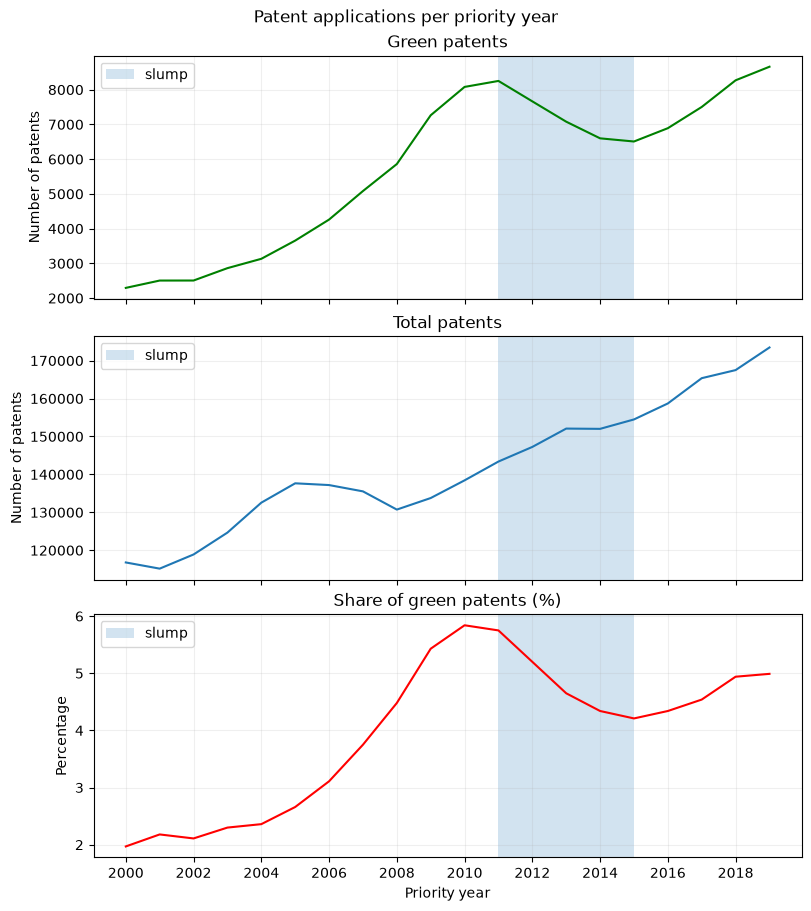

In [155]:
# One figure with 3 panels stacked vertically, sharing the x-axis
fig, axes = plt.subplots(3, 1, figsize=(8, 9), layout='constrained', sharex=True)

# Set the x-values to be the index (the years)
xvalues = patenttypes.index

# First panel: the number of green patents
axes[0].plot(xvalues, patenttypes['green_patents'])
axes[0].set_title('Green patents')
axes[0].set_ylabel('Number of patents')

# Second panel: the total number of patents
axes[1].plot(xvalues, patenttypes['all_patents'])
axes[1].set_title('Total patents')
axes[1].set_ylabel('Number of patents')

# Third panel: the share of green patents.
# Only the bottom panel needs an x-axis label, since the x-axis is shared
axes[2].plot(xvalues, patenttypes['green_share'])
axes[2].set_title('Share of green patents (%)')
axes[2].set_ylabel('Percentage')
axes[2].set_xlabel('Priority year')
axes[2].set_xticks(range(2000, 2020, 2))

fig.suptitle('Patent applications per priority year')

# Shade the slump in grey and add a light grid in every panel
for ax in axes:
    ax.axvspan(slump_s, slump_e, color='grey', alpha=0.2, label='Slump')
    ax.grid(alpha=0.2)

# One legend is enough, so only add it to the top panel
axes[0].legend(loc='upper left')

# Show the figure (and stop Jupyter from printing the legend object)
plt.show()

## Answers to task 2 - Development in green energy patents 2000-2019

The number of green patents was increasing a lot during the 2000s, with the number of green patents peaking in 2011. The number of green patents at the peak in 2011 was 8,251, before falling until 2015, when there were 6,508. After this the number of green patents rises again.

There is a slump between the peak in 2011 and the low in 2015. After 2015 it has been increasing again, reaching 8,660 in 2019, which is higher than the peak in 2011.

The slump is specific to green energy. During the slump the total number of patents grew by 7.7%, while the number of green patents fell by 21.1%.